# GridWorld enhancement 1: cost TD-PMD and Bellman validation


The target policy starts uniform; the separate behavior policy stays uniform.

The plots show **current values only**, together with state and state–action
coverage. Full Q histories and
the existing running-mean arrays are still saved for later analysis.

| Quantity | Meaning |
|---|---|
| $V^{\pi_k}(0)$ | Actual expected discounted cost of the saved policy, calculated by solving its Bellman equation |
| $\widehat V_k(0)=\sum_a\pi_k(a\mid0)Q^k(0,a)$ | Action-weighted estimate from the learned cost critic |

History row k stores the matching policy, Q, and critic value after k updates,
at kB training samples. Row 0 is initialization. Bellman evaluation is performed
after training, uses the saved policies, and never enters a learning update.

Run from top to bottom. Dependencies: NumPy, pandas, Matplotlib, and IPython.
The cumulative-training-samples plot compares **(B, K) = (50, 20000),
(500, 2000), and (5000, 200)**, each with its own critic and Bellman
curves. The iteration plot, coverage, error report, rollout check, and
full-history archive still use the **B = 50, K = 20000** reference run.

All three runs start from state 0 with the same seed and settings. Each
collects **1,000,000 training transitions**, for **3,000,000** across all three
runs. Execution can take several minutes.
The separate rollout check verifies Bellman evaluation; it does not train the
policy and its samples are not included in the training sample count.


**Tuning, seeds, and baseline comparison (last section).** The final section
uses the baseline's observation budget (15M, read from `results/gridworld_baseline.npz`).
It tunes $(\eta, B, Q^0)$ with 10% of that budget, runs the **baseline setting**
(the baseline's $\eta$) and the tuned configuration on five seeds, and compares
both with the baseline. **Run `gridworld_baseline.ipynb` first** and keep
`gridworld_results.py` in the same folder. The reference run above keeps its
own 1M-sample length.

> **Step 1. Requested experiment settings**
>
> $$K=20000,\ B=50,\ \gamma=0.9,\ \eta=0.1,\ \alpha=1,\ \vartheta=1.$$
>
> These are the selected settings for the B = 50 reference run. Passing the checks below does
> not by itself establish convergence or optimality.


In [ ]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display
from matplotlib.ticker import NullFormatter

from gridworld_results import (
    SEEDS, BASELINE_COLOR, SERIES_COLORS, INK, MUTED, optimal_values, save_runs, load_runs,
    sample_grid, on_grid, mean_ci, format_mean_ci, apply_plot_style, plot_band, save_figure,
)

N_ITERS = 20000
B = 50
GAMMA = 0.9
ETA = 0.1
ALPHA = 1.0
THETA = 1.0
SEED = 0

# The sample-count plot compares these runs; B and N_ITERS remain the reference.
# COMPARISON_CONFIGS = ((B, N_ITERS), (500, 2000), (5000, 200))

# The environment constants and layout are the same as in the baseline.
P_INTENDED = 0.8
Q_MOVE = 0.2   # From a goal/hazard: move with .2; return to origin with .8.
C_GOAL, C_REGULAR, C_HAZARD = 0.0, 0.2, 1.0

LAYOUT = (
    "O........G",
    "..H....H..",
    ".....H....",
    ".H......H.",
    "..........",
    "...H.G....",
    "......H...",
    ".H........",
    "....H...H.",
    ".........G",
)
grid = np.array([list(row) for row in LAYOUT])
N_ROWS, N_COLS = grid.shape
N_STATES, N_ACTIONS = grid.size, 4
GOALS = set(np.flatnonzero(grid.ravel() == "G"))
HAZARDS = set(np.flatnonzero(grid.ravel() == "H"))
ORIGIN = int(np.flatnonzero(grid.ravel() == "O")[0])
REPORT_STATE = ORIGIN
ACTION_NAMES = ("up", "right", "down", "left")
DIRECTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))

# Save learning and validation histories in one portable NumPy archive.
OUTPUT_DIR = Path(f"enhancement1_B{B}_K{N_ITERS}_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert grid.shape == (10, 10)
assert len(GOALS) == 3 and len(HAZARDS) == 10
assert ORIGIN == 0
assert np.count_nonzero(grid == "O") == 1
assert ORIGIN not in GOALS | HAZARDS and GOALS.isdisjoint(HAZARDS)
assert 0 <= GAMMA < 1 and ETA >= 0 and 0 < ALPHA <= 1
assert THETA == 1.0, "This experiment uses the confirmed uniform weights."

> **Environment. Same state numbering and costs**
>
> $$s=10r+c.$$
>
> $$C(s)=\begin{cases}0&s\in\mathcal G\\1&s\in\mathcal H\\0.2&\text{otherwise.}\end{cases}$$
>
> O is the origin, G a goal, and H a hazard. Goals and hazards are continuing
> states with the baseline's probabilistic return-to-origin rule.


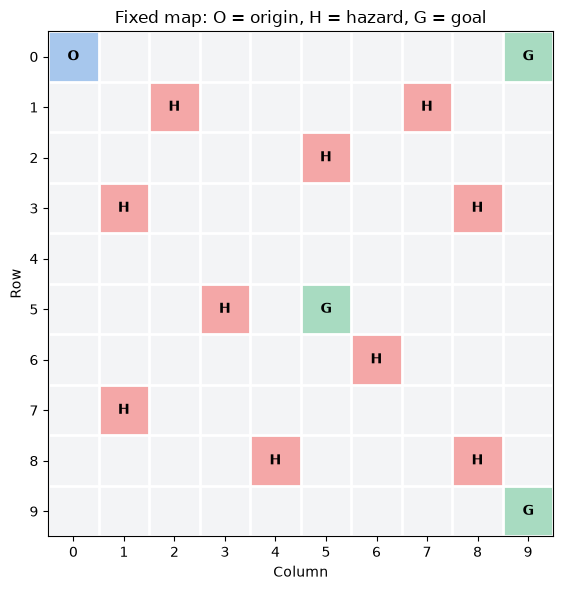

In [2]:
# The colors and letters show the fixed environment, not a learned policy.
colors = {".": 0, "H": 1, "G": 2, "O": 3}
map_colors = np.array([[colors[cell] for cell in row] for row in grid])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(map_colors, cmap=ListedColormap(["#f3f4f6", "#f4a7a7", "#a8dbc1", "#a7c7ed"]),
          vmin=0, vmax=3)
for (row, col), cell in np.ndenumerate(grid):
    if cell != ".":
        ax.text(col, row, cell, ha="center", va="center", fontweight="bold")
ax.set(xticks=range(N_COLS), yticks=range(N_ROWS), xlabel="Column", ylabel="Row",
       title="Fixed map: O = origin, H = hazard, G = goal")
ax.set_xticks(np.arange(-0.5, N_COLS, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N_ROWS, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()


> **Environment. Same transition law**
>
> $$
> \begin{aligned}p(d\mid a)&=\begin{cases}0.8&d=a\\0.2/3&d\ne a,\end{cases}\\P(\cdot\mid s,a)&=\begin{cases}0.8\delta_0+0.2P_{\rm move}(\cdot\mid s,a)&s\in\mathcal G\cup\mathcal H\\P_{\rm move}(\cdot\mid s,a)&\text{otherwise.}\end{cases}\end{aligned}
> $$
>
> Costs are charged at the current state, exactly as in the baseline. The environment has no access to Q or to the target policy.

In [3]:
def move(state, direction):
    """Attempt one direction; clipping implements the baseline wall rule."""
    row, col = divmod(state, N_COLS)
    dr, dc = DIRECTIONS[direction]
    row = min(max(row + dr, 0), N_ROWS - 1)
    col = min(max(col + dc, 0), N_COLS - 1)
    return row * N_COLS + col


class GridWorld:
    def __init__(self):
        # A new experiment starts at the origin; batch boundaries do not reset it.
        self.state = ORIGIN
        self.move_probs = np.full(
            (N_ACTIONS, N_ACTIONS), (1 - P_INTENDED) / 3
        )
        np.fill_diagonal(self.move_probs, P_INTENDED)

    def step(self, action, rng):
        """Take one online interaction and return its cost and next state."""
        state = self.state
        cost = C_GOAL if state in GOALS else C_HAZARD if state in HAZARDS else C_REGULAR
        if state in GOALS | HAZARDS and rng.random() < 1 - Q_MOVE:
            next_state = ORIGIN
        else:
            direction = rng.choice(N_ACTIONS, p=self.move_probs[action])
            next_state = move(state, direction)
        self.state = next_state
        return cost, next_state


> **Step 2. Initialize the cost critic at 10**
>
> $$r=1-c.$$
>
> $$Q^{\pi}_{\rm reward}=\frac1{1-\gamma}-Q^{\pi}_{\rm cost}.$$
>
> $$Q^0_{\rm reward}=0\Longleftrightarrow Q^0_{\rm cost}=\frac1{1-\gamma}=10.$$
>
> $$\pi_b(a\mid s)=\pi_0(a\mid s)=\tfrac14,\ S_0=0,\ N_0=0.$$
>
> Initialize once per run, then carry Q forward. The policy arrays are
> separate, and the simulator continues to return costs.


In [4]:
def initialize_learning(gamma=GAMMA, initial_q=None):
    if not 0 <= gamma < 1:
        raise ValueError("gamma must lie in [0, 1).")
    behavior_policy = np.full((N_STATES, N_ACTIONS), 1.0 / N_ACTIONS)
    target_policy = behavior_policy.copy()
    # Default: equivalent to the paper's zero reward critic under reward = 1 - cost.
    if initial_q is None:
        initial_q = 1.0 / (1.0 - gamma)
    q_values = np.full((N_STATES, N_ACTIONS), initial_q, dtype=float)
    return behavior_policy, target_policy, q_values

> **Step 3. Uniform batch weights**
>
> $$\vartheta=1\Longrightarrow w_t=\frac1B.$$
>
> $$\sum_{t=0}^{B-1}w_t=1.$$
>
> Weights are normalized over the whole batch, not separately for each pair.


In [5]:
def uniform_batch_weights(batch_size):
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")
    return np.full(batch_size, 1.0 / batch_size, dtype=float)


> **Step 4. KL policy update for cost minimization**
>
> $$\pi_{k+1}(a\mid s)=\frac{\pi_k(a\mid s)e^{-\eta Q^k_{\rm cost}(s,a)}}{\sum_b\pi_k(b\mid s)e^{-\eta Q^k_{\rm cost}(s,b)}}.$$



In [6]:
def kl_policy_update(policy, q_values, eta):
    """Apply the baseline KL formula without modifying its input arrays."""
    if eta < 0:
        raise ValueError("eta must be nonnegative.")
    if eta == 0:
        return policy.copy()
    scores = -eta * q_values
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


> **Steps 5–8. Freeze the tables and accumulate TD errors**
>
> $$U^k(s')=\sum_b\pi_{k+1}(b\mid s')Q^k(s',b).$$
>
> $$Y_t=C_t+\gamma U^k(S_{t+1}).$$
>
> $$e_t=Y_t-Q^k(S_t,A_t).$$
>
> $$D_k(s,a)=\sum_{t=0}^{B-1}w_t\mathbf1_{\{(S_t,A_t)=(s,a)\}}e_t.$$
>
> Actions come from the fixed behavior policy. Q and the updated target policy
> remain frozen for the whole batch, so next-state expectations can be
> calculated once per batch.


In [7]:
def collect_td_errors(env, q_old, target_policy, behavior_policy,
                      weights, gamma, rng):
    """Collect one batch and return its weighted TD-error sum and visit counts."""
    n_states, n_actions = q_old.shape
    td_sum = np.zeros_like(q_old)
    visits = np.zeros(q_old.shape, dtype=np.int64)
    start_state = env.state

    # This is exactly the target-policy expectation using the frozen old Q.
    expected_future = np.sum(target_policy * q_old, axis=1)

    for weight in weights:
        state = env.state
        action = int(rng.choice(n_actions, p=behavior_policy[state]))
        cost, next_state = env.step(action, rng)

        td_target = cost + gamma * expected_future[next_state]
        td_error = td_target - q_old[state, action]
        td_sum[state, action] += weight * td_error
        visits[state, action] += 1

        # Q is not updated here. env.step already advanced the environment.

    return {
        "td_sum": td_sum,
        "visits": visits,
        "start_state": start_state,
        "end_state": env.state,
    }


> **Steps 9 and 11. Update Q once and calculate the critic value**
>
> $$Q^{k+1}=Q^k+\alpha D_k.$$
>
> $$\widehat V_{k+1}(s)=\sum_a\pi_{k+1}(a\mid s)Q^{k+1}(s,a).$$
>
> An unvisited pair has D = 0 and keeps its old Q entry. There is no division
> by pair visit counts, threshold fallback, or running mean in these updates.


In [8]:
def critic_update(q_old, td_sum, alpha):
    if not 0 < alpha <= 1:
        raise ValueError("alpha must be in (0, 1].")
    return q_old + alpha * td_sum


def weighted_values(policy, q_values):
    """Return one current critic-based value estimate for every state."""
    return np.sum(policy * q_values, axis=1)


> **Steps 4–11 together. One complete experiment**
>
> $$(\pi_k,Q^k)\longmapsto\pi_{k+1}\longmapsto D_k\longmapsto Q^{k+1}.$$
>
> $$S_0^{k+1}=S_B^k.$$
>
> $$N_{k+1}=N_k+B.$$
>
> Create the environment once per experiment. History row k records the policy,
> Q, and critic V after k completed rounds, including initialization at row 0.


In [9]:
def run_expected_td_pmd(batch_size, n_iters=N_ITERS, gamma=GAMMA,
                        eta=ETA, alpha=ALPHA, seed=SEED, initial_q=None, verbose=True,
                        record_iterations=None):
    """Run the PDF's constant-step-size Expected TD-PMD algorithm.

    record_iterations=None stores the tables after every iteration (reference run).
    For long runs, pass the iterations to store; 0 and n_iters are always added.
    """
    if not isinstance(n_iters, (int, np.integer)) or n_iters <= 0:
        raise ValueError("n_iters must be a positive integer.")
    if not 0 <= gamma < 1 or eta < 0 or not 0 < alpha <= 1:
        raise ValueError("Require 0 <= gamma < 1, eta >= 0, and 0 < alpha <= 1.")

    rng = np.random.default_rng(seed)
    env = GridWorld()
    behavior_policy, policy, q_values = initialize_learning(gamma, initial_q)
    weights = uniform_batch_weights(batch_size)

    # Which iterations to store. Every iteration by default; a subset for long runs,
    # where storing every table would need about 1 GB per array.
    keep_every_iteration = record_iterations is None
    if keep_every_iteration:
        iterations = np.arange(n_iters + 1)
    else:
        iterations = np.unique(np.concatenate(
            [[0, n_iters], np.asarray(record_iterations, dtype=np.int64)]
        ))
        if iterations.min() < 0 or iterations.max() > n_iters:
            raise ValueError("record_iterations must lie in [0, n_iters].")
    row_of = np.full(n_iters + 1, -1, dtype=np.int64)
    row_of[iterations] = np.arange(len(iterations))
    samples = iterations.astype(np.int64) * batch_size

    # Store the complete tables, not only state 0, for Bellman validation after training.
    q_history = np.empty((len(iterations), N_STATES, N_ACTIONS))
    policy_history = np.empty_like(q_history)
    v_history = np.empty((len(iterations), N_STATES))
    batch_visits = (np.empty((n_iters, N_STATES, N_ACTIONS), dtype=np.int64)
                    if keep_every_iteration else None)
    total_visits = np.zeros((N_STATES, N_ACTIONS), dtype=np.int64)
    batch_start_states = np.empty(n_iters, dtype=np.int64)
    batch_end_states = np.empty(n_iters, dtype=np.int64)

    q_history[0] = q_values
    policy_history[0] = policy
    v_history[0] = weighted_values(policy, q_values)
    started = time.perf_counter()

    for k in range(n_iters):
        # Actor first: the new policy is based on the previous critic.
        policy_next = kl_policy_update(policy, q_values, eta)
        batch = collect_td_errors(
            env, q_values, policy_next, behavior_policy, weights, gamma, rng
        )

        # Critic second: one update after all B transitions.
        q_next = critic_update(q_values, batch["td_sum"], alpha)
        row = row_of[k + 1]
        if row >= 0:
            q_history[row] = q_next
            policy_history[row] = policy_next
            v_history[row] = weighted_values(policy_next, q_next)
        if keep_every_iteration:
            batch_visits[k] = batch["visits"]
        total_visits += batch["visits"]
        batch_start_states[k] = batch["start_state"]
        batch_end_states[k] = batch["end_state"]

        # Replace the learning tables; continue from env's existing state.
        policy, q_values = policy_next, q_next

        if verbose and ((k + 1) % max(1, n_iters // 10) == 0 or k == 0):
            elapsed = time.perf_counter() - started
            print(
                f"B={batch_size:,} | round {k + 1:6d}/{n_iters} | "
                f"samples={(k + 1) * batch_size:,} | "
                f"estimated V(0)={policy_next[REPORT_STATE] @ q_next[REPORT_STATE]:.6f} | "
                f"{elapsed:.1f}s",
                flush=True,
            )

    return {
        "B": batch_size,
        "iterations": iterations,
        "samples": samples,
        "q_history": q_history,
        "policy_history": policy_history,
        "v_history": v_history,
        "batch_visits": batch_visits,
        "total_visits": total_visits,
        "batch_start_states": batch_start_states,
        "batch_end_states": batch_end_states,
        "behavior_policy": behavior_policy.copy(),
        "final_policy": policy.copy(),
        "final_q": q_values.copy(),
        "elapsed_seconds": time.perf_counter() - started,
        "initial_q": float(q_history[0, 0, 0]),
        "gamma": gamma, "eta": eta, "alpha": alpha, "theta": 1.0, "seed": seed,
    }

> **Independent policy evaluation model**
>
> $$P_\pi(s,s')=\sum_a\pi(a\mid s)P(s'\mid s,a).$$
>
> $$c_\pi(s)=\sum_a\pi(a\mid s)c(s,a).$$
>
> $$(I-\gamma P_\pi)V^\pi=c_\pi.$$
>
> Build P and c from the map and transition rules. Goals and hazards retain
> their probabilistic return-to-origin transitions. These helpers are used
> only for validation, never for training.


In [10]:
def build_evaluation_model():
    """Independently construct P[state, action, next_state] and c[state, action]."""
    transitions = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    costs = np.empty((N_STATES, N_ACTIONS))
    # Explicit directions prevent this model from relying on move().
    directions = ((-1, 0), (0, 1), (1, 0), (0, -1))

    for state in range(N_STATES):
        row, col = divmod(state, N_COLS)
        cell = grid[row, col]
        costs[state, :] = C_GOAL if cell == "G" else C_HAZARD if cell == "H" else C_REGULAR
        move_probability = Q_MOVE if cell in ("G", "H") else 1.0
        for action in range(N_ACTIONS):
            transitions[state, action, ORIGIN] += 1.0 - move_probability
            for direction, (dr, dc) in enumerate(directions):
                next_row = max(0, min(N_ROWS - 1, row + dr))
                next_col = max(0, min(N_COLS - 1, col + dc))
                next_state = next_row * N_COLS + next_col
                probability = P_INTENDED if direction == action else (1.0 - P_INTENDED) / 3
                # += is necessary: walls and reset transitions can share a destination.
                transitions[state, action, next_state] += move_probability * probability

    np.testing.assert_allclose(transitions.sum(axis=2), 1.0, atol=1e-14)
    assert np.all(transitions >= 0)
    return transitions, costs


def evaluate_policy_bellman(policy, transitions, costs, gamma):
    """Solve for the value of this particular policy, without policy optimization."""
    np.testing.assert_allclose(policy.sum(axis=1), 1.0, atol=1e-12)
    p_policy = np.einsum("sa,san->sn", policy, transitions)
    c_policy = np.sum(policy * costs, axis=1)
    values = np.linalg.solve(np.eye(len(policy)) - gamma * p_policy, c_policy)
    residual = np.max(np.abs(values - c_policy - gamma * p_policy @ values))
    if residual > 1e-10:
        raise AssertionError(f"Bellman residual too large: {residual}")
    return values, residual


P_eval, c_eval = build_evaluation_model()


> **Check the evaluation model against every simulator branch**
>
> $$\sum_{s'}P(s'\mid s,a)=1.$$
>
> $$\|V^\pi-c_\pi-\gamma P_\pi V^\pi\|_\infty\leq10^{-10}.$$
>
> **Purpose:** training uses the simulator (`GridWorld.step`), while the Bellman
> values use the separately built matrix `P_eval` and cost table `c_eval`. The
> Bellman curve is valid only if both describe the same MDP.
>
> **Model match.** For all 400 state-action pairs, force every simulator outcome
> (the reset branch at goals and hazards, and each of the 4 movement directions)
> and add up the resulting next-state probabilities. The total must equal
> `P_eval` exactly, and every cost must equal `c_eval`.
>
> **Solver sanity checks.** Two cases have answers known by hand:
> - A one-state MDP that stays put with cost 0.2 has value
>   $0.2+0.9(0.2)+0.9^2(0.2)+\dots=0.2/(1-0.9)=2$.
> - With $\gamma=0$, the value equals the immediate expected cost,
>   $V(s)=\sum_a\pi(a\mid s)c(s,a)$.


In [11]:
def check_evaluation_model():
    class ControlledRNG:
        def __init__(self, reset_draw, direction):
            self.reset_draw = reset_draw
            self.direction = direction

        def random(self):
            return self.reset_draw

        def choice(self, n, p):
            return self.direction

    env = GridWorld()
    simulator_transitions = np.zeros_like(P_eval)
    for state in range(N_STATES):
        motion = Q_MOVE if state in GOALS | HAZARDS else 1.0
        for action in range(N_ACTIONS):
            if state in GOALS | HAZARDS:
                env.state = state
                cost, next_state = env.step(action, ControlledRNG(0.0, 0))
                assert cost == c_eval[state, action] and next_state == ORIGIN
                simulator_transitions[state, action, next_state] += 1.0 - motion
            for direction in range(N_ACTIONS):
                env.state = state
                cost, next_state = env.step(action, ControlledRNG(1.0, direction))
                assert cost == c_eval[state, action]
                simulator_transitions[state, action, next_state] += motion * env.move_probs[action, direction]
    np.testing.assert_allclose(simulator_transitions, P_eval, atol=1e-14)

    value, _ = evaluate_policy_bellman(np.ones((1, 1)), np.ones((1, 1, 1)), np.array([[0.2]]), 0.9)
    np.testing.assert_allclose(value, [2.0])
    uniform_policy = np.full((N_STATES, N_ACTIONS), 1.0 / N_ACTIONS)
    immediate_value, _ = evaluate_policy_bellman(uniform_policy, P_eval, c_eval, 0.0)
    np.testing.assert_allclose(immediate_value, np.sum(uniform_policy * c_eval, axis=1))
    print("PASS: Bellman model matches all simulator outcomes, including walls and resets.")


check_evaluation_model()


PASS: Bellman model matches all simulator outcomes, including walls and resets.


> **Run the selected reference experiment**
>
> $$B=50,\ K=20000,\ \eta=0.1.$$
>
> $$N_k=kB,\ Q^0=10.$$
>
> One continuous behavior-policy trajectory supplies the learning data.
> Training uses no transition matrix or Bellman solution.


In [12]:
run = run_expected_td_pmd(B)

# Every learning-history row is aligned with its policy and sample count.
Q_history = run["q_history"]
Pi_history = run["policy_history"]
V_critic_history = run["v_history"]
iterations = run["iterations"]
samples = run["samples"]
visit_history = run["batch_visits"]

assert np.isfinite(Q_history).all() and np.isfinite(Pi_history).all()
assert Q_history.min() >= -1e-10 and Q_history.max() <= 1 / (1 - GAMMA) + 1e-10
assert Pi_history.min() >= 0
np.testing.assert_allclose(Pi_history.sum(axis=2), 1.0, atol=1e-12)
np.testing.assert_allclose(V_critic_history, np.sum(Pi_history * Q_history, axis=2))
np.testing.assert_allclose(Q_history[0], 1 / (1 - GAMMA))
np.testing.assert_array_equal(samples, iterations * B)
np.testing.assert_array_equal(visit_history.sum(axis=(1, 2)), np.full(N_ITERS, B))
np.testing.assert_array_equal(run["batch_start_states"][1:], run["batch_end_states"][:-1])
unseen = visit_history == 0
np.testing.assert_array_equal(Q_history[1:][unseen], Q_history[:-1][unseen])

# Independently check every saved actor update, rather than only row sums.
expected_policies = Pi_history[:-1] * np.exp(-ETA * Q_history[:-1])
expected_policies /= expected_policies.sum(axis=2, keepdims=True)
np.testing.assert_allclose(Pi_history[1:], expected_policies, atol=1e-13)
print("PASS: full learning histories, initialization, update formula, and indexing.")


B=50 | round      1/20000 | samples=50 | estimated V(0)=9.968000 | 0.0s
B=50 | round   2000/20000 | samples=100,000 | estimated V(0)=2.007886 | 1.6s
B=50 | round   4000/20000 | samples=200,000 | estimated V(0)=2.008277 | 3.2s
B=50 | round   6000/20000 | samples=300,000 | estimated V(0)=2.007702 | 4.6s
B=50 | round   8000/20000 | samples=400,000 | estimated V(0)=2.005171 | 6.2s
B=50 | round  10000/20000 | samples=500,000 | estimated V(0)=2.005453 | 7.6s
B=50 | round  12000/20000 | samples=600,000 | estimated V(0)=2.003627 | 8.9s
B=50 | round  14000/20000 | samples=700,000 | estimated V(0)=2.006564 | 10.3s
B=50 | round  16000/20000 | samples=800,000 | estimated V(0)=2.006068 | 11.7s
B=50 | round  18000/20000 | samples=900,000 | estimated V(0)=2.006008 | 13.1s
B=50 | round  20000/20000 | samples=1,000,000 | estimated V(0)=2.007287 | 14.5s
PASS: full learning histories, initialization, update formula, and indexing.


> **Evaluate every saved policy after training**
>
> $$V^{\pi_k}=(I-\gamma P_{\pi_k})^{-1}c_{\pi_k}.$$
>
> $$Q^{\pi_k}(s,a)=c(s,a)+\gamma\sum_{s'}P(s'\mid s,a)V^{\pi_k}(s').$$
>
> The reported error is the absolute value-estimation error at state 0:
>
> $$e_k(0)=\left|\widehat V_k(0)-V^{\pi_k}(0)\right|.$$
>
> Row k evaluates the saved policy at kB samples. These are the actual values
> of the learned policies, not optimal-policy values. Exact and critic Q/V
> histories are both stored to permit comparison; Q is not plotted.


In [13]:
V_bellman_history = np.empty_like(V_critic_history)
Q_bellman_history = np.empty_like(Q_history)
bellman_residuals = np.empty(N_ITERS + 1)

for k, policy in enumerate(Pi_history):
    values, residual = evaluate_policy_bellman(policy, P_eval, c_eval, GAMMA)
    V_bellman_history[k] = values
    Q_bellman_history[k] = c_eval + GAMMA * np.einsum("san,n->sa", P_eval, values)
    bellman_residuals[k] = residual

np.testing.assert_allclose(V_bellman_history, np.sum(Pi_history * Q_bellman_history, axis=2), atol=1e-12)
# Absolute error of the action-weighted value estimate at state 0.
critic_error_state0 = np.abs(
    V_critic_history[:, REPORT_STATE] - V_bellman_history[:, REPORT_STATE]
)
evaluation_summary = pd.DataFrame({
    "round": iterations,
    "training_samples": samples,
    "critic_V0": V_critic_history[:, REPORT_STATE],
    "bellman_V0": V_bellman_history[:, REPORT_STATE],
    "V0_error_abs": critic_error_state0,
})
display(evaluation_summary.iloc[[0, 1, 10, 50, N_ITERS]].round(6))
print(f"Largest Bellman residual: {bellman_residuals.max():.3e}")
print(f"Actual cost: {V_bellman_history[0, REPORT_STATE]:.6f} -> {V_bellman_history[-1, REPORT_STATE]:.6f}")


,round,training_samples,critic_V0,bellman_V0,V0_error_abs
0,0,0,10.000000,2.367190,7.632810
1,1,50,9.968000,2.367190,7.600810
10,10,500,9.591933,2.365183,7.226750
50,50,2500,8.279816,2.249267,6.030549
20000,20000,1000000,2.007287,2.006099,0.001188


Largest Bellman residual: 6.439e-15
Actual cost: 2.367190 -> 2.006099


> **Cross-check Bellman values using separate policy rollouts**
>
> $$G_i=\sum_{t=0}^{H-1}\gamma^t C_{i,t}.$$
>
> $$\mathrm{SE}=\frac{\mathrm{sd}(G_1,\ldots,G_M)}{\sqrt M}.$$
>
> $$\mathrm{tail}\leq\frac{\gamma^H}{1-\gamma}.$$
>
> **Purpose:** check that the matrix-based Bellman evaluator agrees with a
> separate simulation of the environment. Freeze the saved initial or final
> target policy, start 20,000 fresh paths from state 0, and average their
> 180-step discounted costs. The average should be close to that policy's
> Bellman value, allowing for sampling error and the small omitted tail.
>
> This is a validation check, not a learning step. It cannot improve or change
> Q or the policy. Its samples are not added to training sample counts. The
> simulation below uses the environment rules, not the Bellman matrix.


In [14]:
def rollout_value_check(policy, gamma, seed, n_paths=20_000, horizon=180):
    """Simulate many independent paths in parallel from the reporting state."""
    rng = np.random.default_rng(seed)
    states = np.full(n_paths, REPORT_STATE, dtype=int)
    returns = np.zeros(n_paths)
    state_cost = np.full(N_STATES, C_REGULAR)
    state_cost[list(GOALS)] = C_GOAL
    state_cost[list(HAZARDS)] = C_HAZARD
    special = np.zeros(N_STATES, dtype=bool)
    special[list(GOALS | HAZARDS)] = True
    action_cdf = policy.cumsum(axis=1)
    action_cdf[:, -1] = 1.0
    move_probabilities = np.full((N_ACTIONS, N_ACTIONS), (1 - P_INTENDED) / 3)
    np.fill_diagonal(move_probabilities, P_INTENDED)
    move_cdf = move_probabilities.cumsum(axis=1)
    move_cdf[:, -1] = 1.0
    directions = np.array(DIRECTIONS)

    for t in range(horizon):
        returns += gamma**t * state_cost[states]
        actions = (rng.random(n_paths)[:, None] > action_cdf[states]).sum(axis=1)
        moves = (rng.random(n_paths)[:, None] > move_cdf[actions]).sum(axis=1)
        reset = special[states] & (rng.random(n_paths) < 1 - Q_MOVE)
        rows = np.clip(states // N_COLS + directions[moves, 0], 0, N_ROWS - 1)
        cols = np.clip(states % N_COLS + directions[moves, 1], 0, N_COLS - 1)
        states = rows * N_COLS + cols
        states[reset] = ORIGIN

    return returns.mean(), returns.std(ddof=1) / np.sqrt(n_paths), gamma**horizon / (1 - gamma)


validation_rows = []
for k, validation_seed in [(0, 20261109), (N_ITERS, 20261110)]:
    mean, standard_error, tail_bound = rollout_value_check(Pi_history[k], GAMMA, validation_seed)
    exact = V_bellman_history[k, REPORT_STATE]
    # A broad statistical check, together with the deterministic model checks above.
    assert abs(mean - exact) <= 6 * standard_error + tail_bound
    validation_rows.append({"round": k, "bellman_V0": exact,
                            "rollout_mean": mean, "standard_error": standard_error,
                            "tail_bound": tail_bound})
rollout_validation = pd.DataFrame(validation_rows)
display(rollout_validation.round(8))
print("PASS: separate policy rollouts agree with Bellman values within sampling uncertainty.")


,round,bellman_V0,rollout_mean,standard_error,tail_bound
0,0,2.367190,2.369777,0.001965,6.000000e-08
1,20000,2.006099,2.005625,0.000286,6.000000e-08


PASS: separate policy rollouts agree with Bellman values within sampling uncertainty.


> **Baseline-style coverage and retained reporting arrays**
>
> $$R_k=\sum_s\mathbf1\{\sum_a n_k(s,a)>0\}.$$
>
> $$C_k=100\frac{\sum_{s,a}\mathbf1\{n_k(s,a)>0\}}{400}\%.$$
>
> These arrays describe the B = 50 reference run. State counts are out of
> 100 and pair coverage is out of 400. Coverage
> describes behavior-policy samples. Existing running-mean arrays are retained
> for compatibility with the saved results, but they are not plotted.


In [15]:
post_iterations = iterations[1:]
post_samples = samples[1:]
critic_running_mean = np.cumsum(V_critic_history[1:, REPORT_STATE]) / post_iterations
bellman_running_mean = np.cumsum(V_bellman_history[1:, REPORT_STATE]) / post_iterations
state_visits = visit_history.sum(axis=2)
states_reached = np.count_nonzero(state_visits, axis=1)
states_ever_reached = np.count_nonzero(state_visits.cumsum(axis=0), axis=1)
pair_coverage_percent = 100 * np.mean(visit_history > 0, axis=(1, 2))
pair_ever_coverage_percent = 100 * np.mean(visit_history.cumsum(axis=0) > 0, axis=(1, 2))

for j in range(N_ITERS):
    observed_pairs = np.argwhere(visit_history[j] > 0)
    assert states_reached[j] == len(set(observed_pairs[:, 0]))
    np.testing.assert_allclose(pair_coverage_percent[j], 100 * len(observed_pairs) / (N_STATES * N_ACTIONS))
    np.testing.assert_allclose(critic_running_mean[j], V_critic_history[1:j+2, REPORT_STATE].mean())
    np.testing.assert_allclose(bellman_running_mean[j], V_bellman_history[1:j+2, REPORT_STATE].mean())
assert np.all(np.diff(states_ever_reached) >= 0)
assert np.all(np.diff(pair_ever_coverage_percent) >= 0)
print(f"Distinct states per iteration: {states_reached.min()}–{states_reached.max()} out of {N_STATES}.")
print(f"State–action coverage per iteration: {pair_coverage_percent.min():.2f}%–{pair_coverage_percent.max():.2f}%.")


Distinct states per iteration: 4–34 out of 100.
State–action coverage per iteration: 2.75%–12.00%.


> **Save all learning and evaluation arrays**
>
> $$Q_{\rm hist}[k,s,a]=Q^k(s,a).$$
>
> $$\Pi_{\rm hist}[k,s,a]=\pi_k(a\mid s).$$
>
> $$V_{\rm Bellman}[k,s]=V^{\pi_k}(s).$$
>
> This archive stores the B = 50, K = 20000 reference run and has no leading
> B axis. Q, policy, and V histories have 20001 rows including initialization.
> Coverage and retained running-mean arrays have 20000 rows, aligned with
> post_iterations and post_samples.


In [16]:
results_path = OUTPUT_DIR / f"gridworld_enhancement1_B{B}_K{N_ITERS}_results.npz"
np.savez_compressed(
    results_path,
    B=B, n_iters=N_ITERS, gamma=GAMMA, eta=ETA, alpha=ALPHA, theta=THETA,
    initial_q=run["initial_q"], seed=SEED, report_state=REPORT_STATE, origin=ORIGIN,
    iterations=iterations, samples=samples,
    post_iterations=post_iterations, post_samples=post_samples,
    Q_history=Q_history, policy_history=Pi_history,
    V_critic_history=V_critic_history, V_bellman_history=V_bellman_history,
    Q_bellman_history=Q_bellman_history, bellman_residuals=bellman_residuals,
    critic_error_state0=critic_error_state0,
    critic_running_mean=critic_running_mean, bellman_running_mean=bellman_running_mean,
    batch_visits=visit_history, state_visits=state_visits,
    states_reached=states_reached, states_ever_reached=states_ever_reached,
    pair_coverage_percent=pair_coverage_percent,
    pair_ever_coverage_percent=pair_ever_coverage_percent,
    batch_start_states=run["batch_start_states"], batch_end_states=run["batch_end_states"],
    behavior_policy=run["behavior_policy"], elapsed_seconds=run["elapsed_seconds"],
    transition_model=P_eval, cost_table=c_eval,
    layout=np.array(LAYOUT), action_names=np.array(ACTION_NAMES), directions=np.array(DIRECTIONS),
    p_intended=P_INTENDED, q_move=Q_MOVE,
    cost_goal=C_GOAL, cost_regular=C_REGULAR, cost_hazard=C_HAZARD,
    rollout_validation_columns=np.array(rollout_validation.columns),
    rollout_validation_values=rollout_validation.to_numpy(),
    rollout_validation_paths=20_000, rollout_validation_horizon=180,
)
with np.load(results_path, allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved["policy_history"], Pi_history)
    np.testing.assert_array_equal(saved["Q_history"], Q_history)
    np.testing.assert_array_equal(saved["V_bellman_history"], V_bellman_history)
    np.testing.assert_array_equal(saved["V_critic_history"], V_critic_history)
print(f"Saved {results_path}")


Saved enhancement1_B50_K20000_outputs/gridworld_enhancement1_B50_K20000_results.npz


> **Reference values versus iterations**
>
> $$y_{k,B}=\widehat V_{k,B}(0)\ \text{or}\ V^{\pi_{k,B}}(0),\quad N_{k,B}=kB.$$
>
> The first figure retains the B = 50 reference critic and Bellman curves
> against completed update rounds.



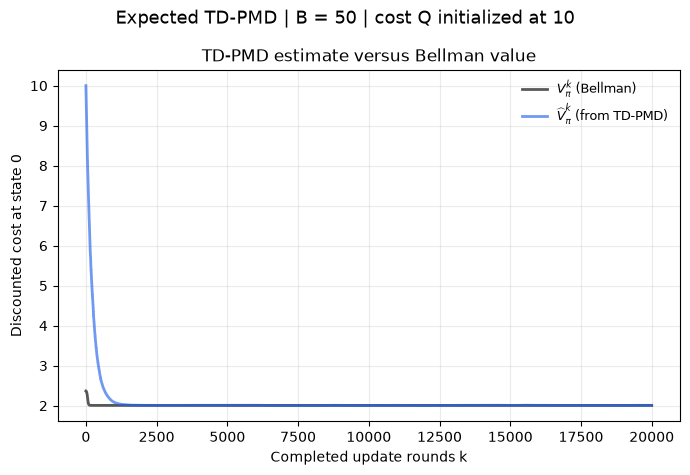

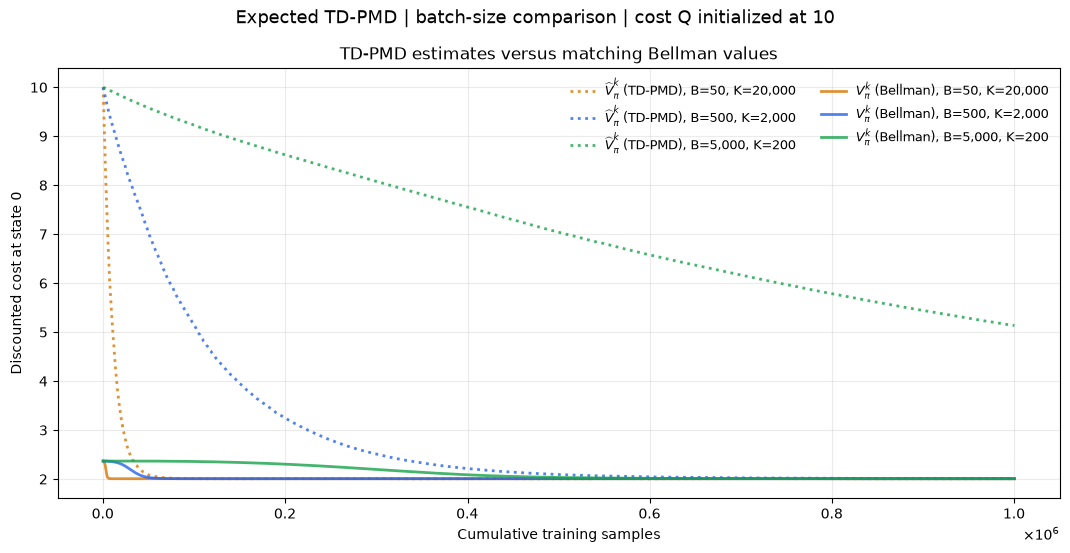

In [ ]:
def plot_value_comparison(x, xlabel):
    fig, ax = plt.subplots(figsize=(7, 4.8))

    exact = V_bellman_history[:, REPORT_STATE]
    estimated = V_critic_history[:, REPORT_STATE]

    ax.plot(
        x, exact,
        linestyle="-", color="black", alpha=0.65, linewidth=2,
        label=r"$V_\pi^k$ (Bellman)"
    )
    ax.plot(
        x, estimated,
        linestyle="-", color="#2563eb", alpha=0.65, linewidth=2,
        label=r"$\widehat{V}_\pi^k$ (from TD-PMD)"
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Discounted cost at state 0")
    ax.set_title("TD-PMD estimate versus Bellman value")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=9)

    fig.suptitle(
        f"Expected TD-PMD | B = {B:,} | cost Q initialized at 10",
        fontsize=13
    )
    fig.tight_layout()
    return fig, ax


# def plot_sample_comparison():
#     fig, ax = plt.subplots(figsize=(10.8, 5.6))
#     # Color identifies B; dotted estimates and solid Bellman values share it.
#     colors = {
#         50: "#d97706",
#         500: "#2563eb",
#         5000: "#16a34a",
#     }
#     critic_lines, bellman_lines = [], []

#     for batch_size, n_rounds in COMPARISON_CONFIGS:
#         comparison_run = comparison_runs[batch_size]
#         x = comparison_run["samples"]
#         estimated = comparison_run["v_history"][:, REPORT_STATE]
#         exact = comparison_bellman_history[batch_size][:, REPORT_STATE]
#         color = colors[batch_size]
#         configuration = f"B={batch_size:,}, K={n_rounds:,}"

#         critic_line, = ax.plot(
#             x, estimated, linestyle=":", color=color,
#             alpha=0.8, linewidth=2,
#             label=rf"$\widehat{{V}}_\pi^k$ (TD-PMD), {configuration}",
#         )
#         bellman_line, = ax.plot(
#             x, exact, linestyle="-", color=color,
#             alpha=0.8, linewidth=2,
#             label=rf"$V_\pi^k$ (Bellman), {configuration}",
#         )
#         critic_lines.append(critic_line)
#         bellman_lines.append(bellman_line)

#     ax.set_xlabel("Cumulative training samples")
#     ax.set_ylabel("Discounted cost at state 0")
#     ax.set_title("TD-PMD estimates versus matching Bellman values")
#     ax.grid(alpha=0.25)
#     ax.legend(handles=critic_lines + bellman_lines, ncol=2,
#               frameon=False, fontsize=9)
#     fig.suptitle("Expected TD-PMD | batch-size comparison | cost Q initialized at 10",
#                  fontsize=13)
#     fig.tight_layout()
#     return fig, ax


# Figure 1: show the B = 50 reference comparison against iterations.
fig, ax = plot_value_comparison(
    iterations, "Completed update rounds k"
)
plt.show()


# # Figure 2: compare all three configurations using their own sample counts.
# fig, ax = plot_sample_comparison()
# ax.ticklabel_format(
#     axis="x", style="sci", scilimits=(6, 6), useMathText=True
# )
# fig.tight_layout()
# plt.show()

> **Baseline-style coverage: this batch and ever visited**
>
> $$\text{states reached}=\#\{s:n_k(s)>0\}.$$
>
> $$\text{pair coverage}=100\frac{\#\{(s,a):n_k(s,a)>0\}}{400}\%.$$
>
> Both panels describe the B = 50 reference run. The first counts distinct
> states out of 100; the second measures
> state–action coverage out of 400 pairs. Cumulative coverage uses all batches
> so far. There is no probability-threshold exclusion in this enhancement.


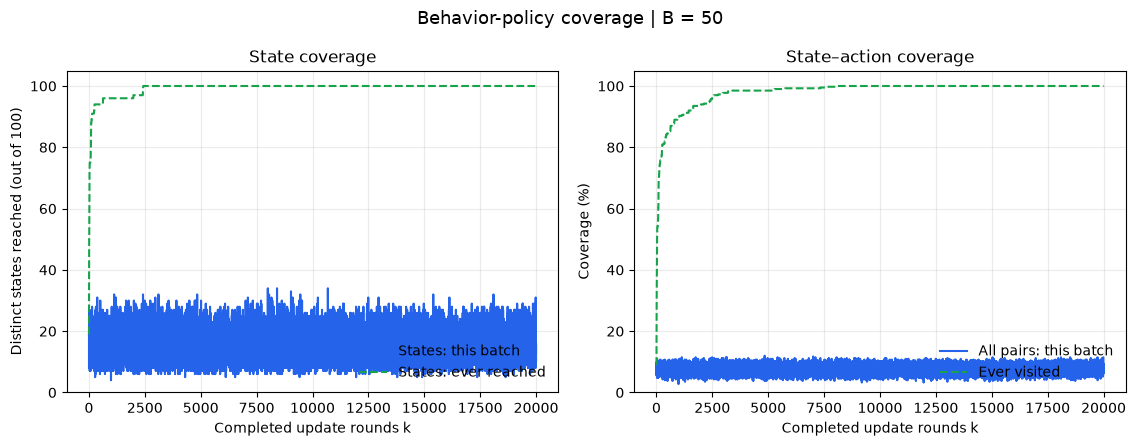

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
axes[0].plot(post_iterations, states_reached, label="States: this batch", color="#2563eb")
axes[0].plot(post_iterations, states_ever_reached, "--", label="States: ever reached", color="#16a34a")
axes[0].set(title="State coverage", ylabel="Distinct states reached (out of 100)")
axes[1].plot(post_iterations, pair_coverage_percent, label="All pairs: this batch", color="#2563eb")
axes[1].plot(post_iterations, pair_ever_coverage_percent, "--", label="Ever visited", color="#16a34a")
axes[1].set(title="State–action coverage", ylabel="Coverage (%)")
for ax in axes:
    ax.set_xlabel("Completed update rounds k")
    ax.set_ylim(0, 105)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, loc="lower right")
fig.suptitle(f"Behavior-policy coverage | B = {B:,}", fontsize=13)
fig.tight_layout()
plt.show()


**Saved reference arrays and interpretation (B = 50, K = 20000)**

| Array | Shape and interpretation |
|---|---|
| `Q_history`, `policy_history`, `Q_bellman_history` | (20001, 100, 4); row k corresponds to policy k after k updates |
| `V_critic_history`, `V_bellman_history` | (20001, 100); all states, including initialization |
| `critic_error_state0` | (N_ITERS + 1,); absolute difference between critic and Bellman values at state 0 |
| `samples`, `iterations` | (20001,); matched to the policy and value rows |
| `critic_running_mean`, `bellman_running_mean` | (20000,); retained in the archive but not plotted |
| `batch_visits` | (20000, 100, 4); row j is the batch producing history row j+1 |
| `states_reached`, `pair_coverage_percent` | (20000,); current-batch coverage |
| `states_ever_reached`, `pair_ever_coverage_percent` | (20000,); cumulative coverage |

Load the archive with `np.load(results_path, allow_pickle=False)`.
Use the current Bellman value to assess each learned policy and the
critic-to-Bellman gap to assess value estimation. Passing the checks validates
the implementation; it does not establish that the critic has converged or
that a policy is optimal.


## Tuning, five seeds, and comparison with the baseline

Everything above describes one reference run (1M samples, the paper's settings).
This section gives TD-PMD **the same observation budget as the baseline**
(15M, read from `results/gridworld_baseline.npz`) and answers three questions.

1. **Which settings?** Grid search over three parameters with three values each,
   every combination run with 10% of the budget (1.5M samples):
   policy stepsize $\eta\in\{0.1,1,10\}$, batch size $B\in\{50,500,5000\}$, and
   initial critic value $Q^0\in\{0,\ 2,\ 10\}$. These three initial values are the
   best possible cost, the cost of staying in ordinary cells forever
   ($0.2/(1-\gamma)$), and the worst possible cost ($1/(1-\gamma)$, the paper's choice).
2. **How reliable?** Two configurations, each on five seeds:
   the **baseline setting** uses the baseline's tuned stepsize $\eta$ with the
   reference run's $B=50$ and $Q^0=10$; the **tuned** setting is the best grid combination.
3. **How does it compare?** Both are plotted with the saved baseline runs.

All comparisons use the exact value $V^{\pi_k}$ of the learned policy and the
optimal value $V^*$. The gap $V^{\pi_k}(s)-V^*(s)$ is reported at state 0 and
averaged over all 100 states. A 15M-sample run with $B=50$ has 300,000
iterations, so these runs store the policy and critic at about 200 log-spaced
iterations (`record_iterations`) instead of at every iteration.

In [21]:
baseline_runs, baseline_settings = load_runs("gridworld_baseline")
V_STAR = optimal_values(P_eval, c_eval, GAMMA)
# Both notebooks must describe the same MDP.
np.testing.assert_allclose(V_STAR, baseline_settings["V_star"], atol=1e-9)

SAMPLE_BUDGET = int(baseline_settings["sample_budget"])   # Same budget as the baseline.
TUNING_BUDGET = SAMPLE_BUDGET // 10                       # 10% for each combination.
BASELINE_ETA = float(baseline_settings["eta"])            # The baseline's tuned stepsize.
ETA_CANDIDATES = (0.1, 1.0, 10.0)
BATCH_CANDIDATES = (50, 500, 5000)
INITIAL_Q_CANDIDATES = (0.0, C_REGULAR / (1 - GAMMA), 1 / (1 - GAMMA))


def gap_at_report_state(values):
    """Optimality gap at the reporting state for a stack of value vectors [n, state]."""
    return values[:, REPORT_STATE] - V_STAR[REPORT_STATE]


def mean_gap(values):
    """Optimality gap averaged over all 100 start states."""
    return (values - V_STAR).mean(axis=1)


def recorded_iterations(n_iters, n_points=200):
    """About n_points log-spaced iterations; the run function adds 0 and n_iters."""
    return np.unique(np.round(np.geomspace(1, n_iters, n_points)).astype(np.int64))


def summarize_run(run):
    """Evaluate every stored policy exactly and keep the curves."""
    values = np.array([
        evaluate_policy_bellman(policy, P_eval, c_eval, GAMMA)[0]
        for policy in run["policy_history"]
    ])
    return {
        "seed": run["seed"],
        "samples": run["samples"],
        "values": values,
        "estimate": run["v_history"][:, REPORT_STATE],
        "seconds": run["elapsed_seconds"],
        "state_visits": run["total_visits"].sum(axis=1),
        "final_policy": run["final_policy"],
    }


print(f"Budget per run: {SAMPLE_BUDGET:,} samples (from the baseline file); "
      f"tuning: {TUNING_BUDGET:,} per combination.")
print(f"Baseline stepsize: eta = {BASELINE_ETA:g}")

Budget per run: 15,000,000 samples (from the baseline file); tuning: 1,500,000 per combination.
Baseline stepsize: eta = 1


In [22]:
tuning_rows = []
for initial_q in INITIAL_Q_CANDIDATES:
    for batch_size in BATCH_CANDIDATES:
        for eta in ETA_CANDIDATES:
            started = time.perf_counter()
            tuning_run = run_expected_td_pmd(
                batch_size, n_iters=TUNING_BUDGET // batch_size, eta=eta,
                seed=SEEDS[0], initial_q=initial_q, verbose=False,
                record_iterations=(),   # Only the first and the final policy are needed.
            )
            final_values = evaluate_policy_bellman(
                tuning_run["final_policy"], P_eval, c_eval, GAMMA
            )[0][None]
            tuning_rows.append({
                "Q0": initial_q, "B": batch_size, "eta": eta,
                "gap_at_state_0": gap_at_report_state(final_values)[0],
                "mean_gap_all_states": mean_gap(final_values)[0],
                "seconds": time.perf_counter() - started,
            })

tuning = pd.DataFrame(tuning_rows).sort_values("gap_at_state_0").reset_index(drop=True)
best = tuning.iloc[0]
BASELINE_SETTING = {"eta": BASELINE_ETA, "batch_size": B, "initial_q": 1 / (1 - GAMMA)}
TUNED = {"eta": float(best["eta"]), "batch_size": int(best["B"]), "initial_q": float(best["Q0"])}
print(f"Tuning budget: {TUNING_BUDGET:,} samples per combination (seed {SEEDS[0]}).")
print(tuning.round(4).to_string(index=False))
print(f"\nBaseline setting: eta = {BASELINE_SETTING['eta']:g}, B = {BASELINE_SETTING['batch_size']}, "
      f"Q0 = {BASELINE_SETTING['initial_q']:g}")
print(f"Tuned:            eta = {TUNED['eta']:g}, B = {TUNED['batch_size']}, Q0 = {TUNED['initial_q']:g}")

Tuning budget: 1,500,000 samples per combination (seed 0).
  Q0    B  eta  gap_at_state_0  mean_gap_all_states  seconds
 2.0   50  1.0          0.0001               0.0120  19.0930
 2.0   50 10.0          0.0002               0.0115  18.8967
 2.0   50  0.1          0.0003               0.0185  19.1316
 2.0  500 10.0          0.0015               0.0636  19.3078
 2.0  500  1.0          0.0017               0.0954  18.5993
10.0   50  1.0          0.0018               0.3742  20.4760
10.0   50  0.1          0.0018               0.3429  20.7713
10.0  500  0.1          0.0022               0.3786  19.3884
10.0  500  1.0          0.0022               0.3876  18.3447
10.0   50 10.0          0.0022               0.4297  20.3814
10.0  500 10.0          0.0024               0.4346  20.2779
10.0 5000  0.1          0.0025               0.3485  19.1139
10.0 5000  1.0          0.0025               0.3602  19.1978
10.0 5000 10.0          0.0025               0.3576  18.7679
 2.0 5000 10.0          0.

**Five seeds for the baseline setting and the tuned configuration.** Each run uses
the baseline's budget. The summaries are saved in the same format as the baseline:
`results/gridworld_enh1_baseline_setting.npz` and `results/gridworld_enh1_tuned.npz`.

In [23]:
CONFIGS = {"baseline_setting": BASELINE_SETTING, "tuned": TUNED}
enh1_runs = {}
for name, config in CONFIGS.items():
    enh1_runs[name] = []
    n_iters = SAMPLE_BUDGET // config["batch_size"]
    for seed in SEEDS:
        full_run = run_expected_td_pmd(
            config["batch_size"], n_iters=n_iters, eta=config["eta"], seed=seed,
            initial_q=config["initial_q"], verbose=False,
            record_iterations=recorded_iterations(n_iters),
        )
        enh1_runs[name].append(summarize_run(full_run))
        print(f"{name}, seed {seed}: {n_iters:,} iterations, "
              f"{full_run['elapsed_seconds']:.0f} s", flush=True)
    path = save_runs(
        f"gridworld_enh1_{name}", enh1_runs[name], **config,
        gamma=GAMMA, alpha=ALPHA, sample_budget=SAMPLE_BUDGET, report_state=REPORT_STATE,
    )
    print(f"Saved {path}")

baseline_setting, seed 0: 300,000 iterations, 197 s
baseline_setting, seed 1: 300,000 iterations, 192 s
baseline_setting, seed 2: 300,000 iterations, 196 s
baseline_setting, seed 3: 300,000 iterations, 196 s
baseline_setting, seed 4: 300,000 iterations, 190 s
Saved results/gridworld_enh1_baseline_setting.npz
tuned, seed 0: 300,000 iterations, 133 s
tuned, seed 1: 300,000 iterations, 98 s
tuned, seed 2: 300,000 iterations, 98 s
tuned, seed 3: 300,000 iterations, 99 s
tuned, seed 4: 300,000 iterations, 98 s
Saved results/gridworld_enh1_tuned.npz


In [24]:
SETTING_LABEL = f"TD-PMD, baseline setting (η = {BASELINE_ETA:g})"
METHODS = {
    "Baseline: SPMD + TOMC": (baseline_runs, int(baseline_settings["sample_budget"]), BASELINE_COLOR),
    SETTING_LABEL: (enh1_runs["baseline_setting"], SAMPLE_BUDGET, SERIES_COLORS[1]),
    "TD-PMD, tuned": (enh1_runs["tuned"], SAMPLE_BUDGET, SERIES_COLORS[0]),
}


def values_at_budget(run, budget):
    """Exact values [state] of the last policy obtained within the sample budget."""
    return run["values"][np.searchsorted(run["samples"], budget, side="right") - 1]


def samples_to_reach(run, target_gap):
    """First recorded sample count at which the gap at state 0 is at most target_gap."""
    reached = gap_at_report_state(run["values"]) <= target_gap
    return run["samples"][np.argmax(reached)] if reached.any() else np.nan


baseline_final_gap = np.mean([
    gap_at_report_state(values_at_budget(run, METHODS["Baseline: SPMD + TOMC"][1])[None])[0]
    for run in baseline_runs
])
summary_rows = []
for label, (runs, budget, _) in METHODS.items():
    final = np.array([values_at_budget(run, budget) for run in runs])
    summary_rows.append({
        "method": label,
        "samples_per_run": f"{budget:,}",
        "seconds_per_run": round(float(np.mean([run["seconds"] for run in runs])), 1),
        "gap_at_state_0": format_mean_ci(gap_at_report_state(final)),
        "mean_gap_all_states": format_mean_ci(mean_gap(final)),
        "samples_to_match_baseline": f"{np.mean([samples_to_reach(run, baseline_final_gap) for run in runs]):,.0f}",
    })
summary = pd.DataFrame(summary_rows)
print(f"Uniform policy: gap at state 0 = {gap_at_report_state(baseline_settings['V_uniform'][None])[0]:.4f}, "
      f"mean gap = {mean_gap(baseline_settings['V_uniform'][None])[0]:.4f}")
print(f"Gaps are mean ± 95% CI over {len(SEEDS)} seeds, at the end of each run.")
print("'samples_to_match_baseline' is the number of samples needed to reach the "
      f"baseline's final gap at state 0 ({baseline_final_gap:.4f}).\n")
print(summary.to_string(index=False))

Uniform policy: gap at state 0 = 0.3629, mean gap = 0.5504
Gaps are mean ± 95% CI over 5 seeds, at the end of each run.
'samples_to_match_baseline' is the number of samples needed to reach the baseline's final gap at state 0 (0.0553).

                          method samples_per_run  seconds_per_run  gap_at_state_0 mean_gap_all_states samples_to_match_baseline
           Baseline: SPMD + TOMC      15,000,000            189.2 0.0553 ± 0.0147     0.1003 ± 0.0139                       nan
TD-PMD, baseline setting (η = 1)      15,000,000            194.2 0.0018 ± 0.0000     0.3361 ± 0.0376                     1,900
                   TD-PMD, tuned      15,000,000            105.1 0.0000 ± 0.0000     0.0058 ± 0.0011                    16,670


**Result figure.** Both panels show the optimality gap of the learned policy
against cumulative training observations on logarithmic axes. Lines are seed
means; bands are 95% confidence intervals. Left: the reporting state. Right:
the average over all 100 states.

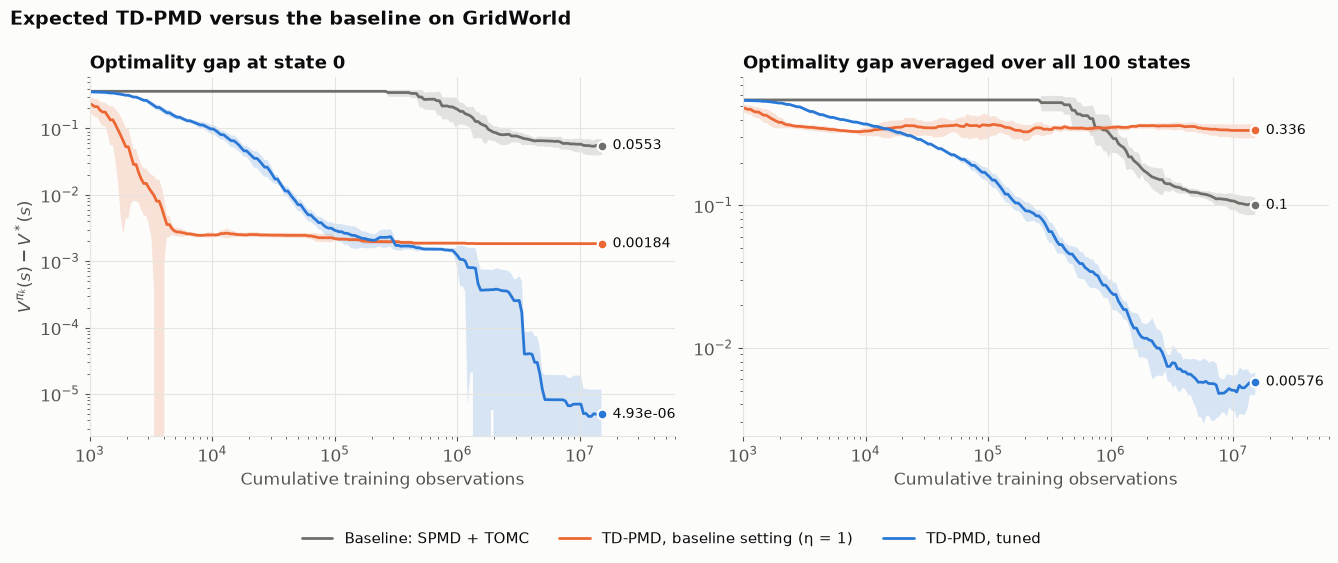

In [25]:
apply_plot_style()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharex=True)
panels = ((gap_at_report_state, "Optimality gap at state 0", 0.6),
          (mean_gap, "Optimality gap averaged over all 100 states", 0.8))


def label_ends(ax, points, min_gap=12):
    """Write each curve's final value at its end, pushed apart so labels never overlap."""
    to_points = 72 / ax.figure.dpi
    previous = -np.inf
    for x, y in sorted(points, key=lambda point: point[1]):
        y_points = ax.transData.transform((x, y))[1] * to_points
        shift = max(0.0, previous + min_gap - y_points)
        ax.annotate(f"{y:.3g}", (x, y), xytext=(8, shift), textcoords="offset points",
                    va="center", color=INK, fontsize=10)
        previous = y_points + shift


ends = {ax: [] for ax in axes}
for ax, (metric, title, top) in zip(axes, panels):
    lowest = np.inf
    for label, (runs, budget, color) in METHODS.items():
        grid_samples = sample_grid(budget)
        curves = [on_grid(run, grid_samples, metric) for run in runs]
        mean = plot_band(ax, grid_samples, curves, color, label)
        lowest = min(lowest, mean[mean > 0].min())
        ax.plot(grid_samples[-1], mean[-1], "o", color=color, markersize=7,
                markeredgecolor="white", markeredgewidth=1.5)
        ends[ax].append((grid_samples[-1], mean[-1]))
    ax.set(title=title, xscale="log", xlabel="Cumulative training observations")
    ax.set_yscale("log", nonpositive="clip")
    ax.set_ylim(lowest / 2, top)
    ax.yaxis.set_minor_formatter(NullFormatter())
axes[0].set_ylabel(r"$V^{\pi_k}(s) - V^*(s)$")
axes[0].set_xlim(1e3, 6e7)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Expected TD-PMD versus the baseline on GridWorld", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.06, 1, 1))
for ax in axes:
    label_ends(ax, ends[ax])
save_figure(fig, "e1_results")
plt.show()

**Where each method is right.** The first map counts how often the uniform
behavior policy visits each state in one run. The other maps show the gap
$V^{\pi}(s)-V^*(s)$ of the final policy at every state (mean over seeds).
TD-PMD learns from the states it visits. Far states are visited rarely, so their
critic entries stay close to the initial value $Q^0$.

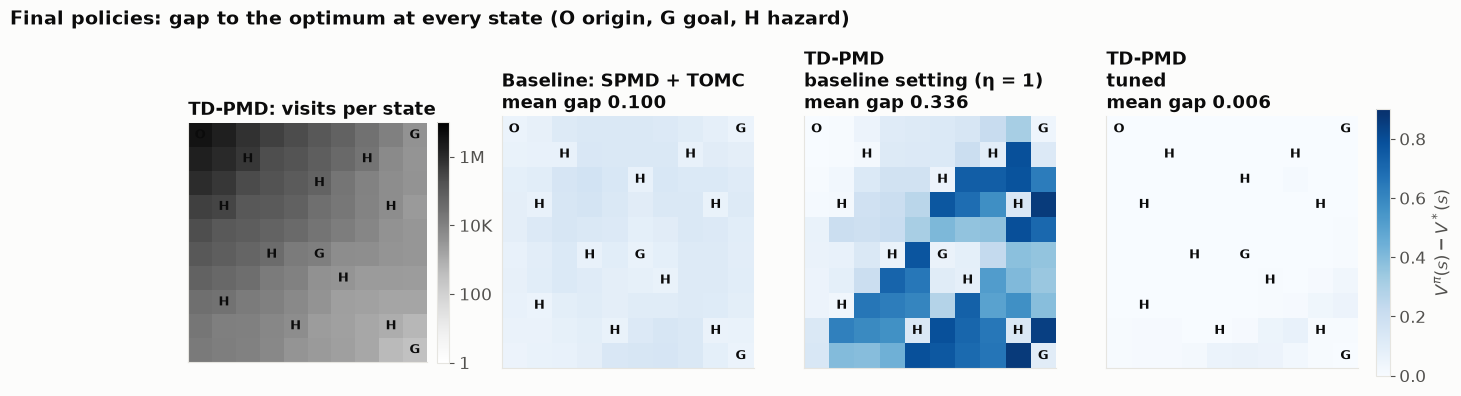

In [26]:
def draw_map(ax, cell_values, title, **image_options):
    image = ax.imshow(cell_values.reshape(N_ROWS, N_COLS), **image_options)
    for (row, col), cell in np.ndenumerate(grid):
        if cell != ".":
            ax.text(col, row, cell, ha="center", va="center", fontsize=9,
                    fontweight="bold", color=INK)
    ax.set(title=title, xticks=[], yticks=[])
    ax.grid(False)
    return image


final_gaps = {
    label: np.mean([values_at_budget(run, budget) - V_STAR for run in runs], axis=0)
    for label, (runs, budget, _) in METHODS.items()
}
visits = np.mean([run["state_visits"] for run in enh1_runs["baseline_setting"]], axis=0)
top_decade = int(np.ceil(np.log10(visits.max())))

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.8))
visit_image = draw_map(axes[0], np.log10(np.maximum(visits, 1)),
                       "TD-PMD: visits per state", cmap="Greys", vmin=0, vmax=top_decade)
for ax, (label, gaps) in zip(axes[1:], final_gaps.items()):
    gap_image = draw_map(ax, gaps, f"{label.replace(', ', chr(10))}\nmean gap {gaps.mean():.3f}",
                         cmap="Blues", vmin=0, vmax=0.9)
decades = list(range(0, top_decade + 1, 2))
visit_bar = fig.colorbar(visit_image, ax=axes[0], fraction=0.046, pad=0.04, ticks=decades)
short = {0: "1", 1: "10", 2: "100", 3: "1K", 4: "10K", 5: "100K", 6: "1M", 7: "10M", 8: "100M"}
visit_bar.ax.set_yticklabels([short[d] for d in decades])
fig.colorbar(gap_image, ax=axes[1:], fraction=0.015, pad=0.02,
             label=r"$V^{\pi}(s) - V^*(s)$")
fig.suptitle("Final policies: gap to the optimum at every state (O origin, G goal, H hazard)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
save_figure(fig, "e1_state_maps")
plt.show()

**How good is each method's own estimate?** The absolute error
$|\widehat V_k(s_0)-V^{\pi_k}(s_0)|$ at state 0. A TOMC estimate is rebuilt from
one first-visit return per action in every iteration, so its error stays at the
noise level. The TD critic is carried from one iteration to the next: it starts
far away (at its initial value) and its error keeps shrinking.

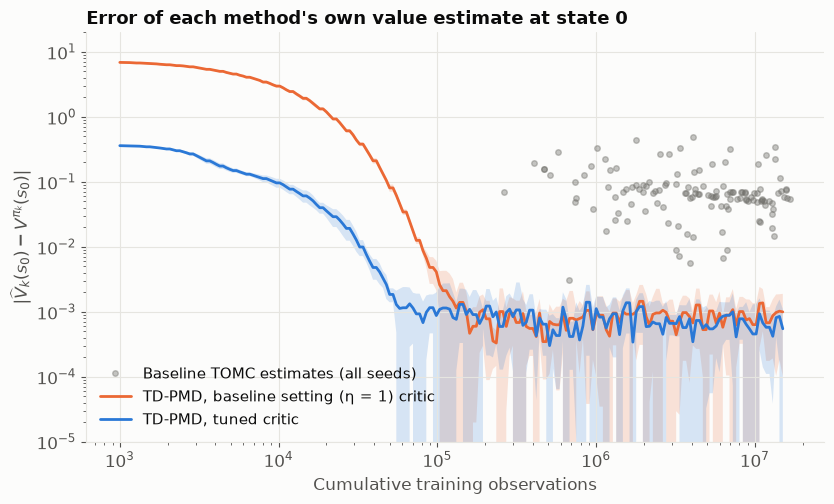

In [27]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for index, run in enumerate(baseline_runs):
    # TOMC estimate k is known once batch k has ended, at samples[k + 1].
    error = np.abs(run["estimate"][:-1] - run["values"][:-1, REPORT_STATE])
    ax.plot(run["samples"][1:], error, "o", color=BASELINE_COLOR, markersize=4, alpha=0.4,
            label="Baseline TOMC estimates (all seeds)" if index == 0 else None)
for label in (SETTING_LABEL, "TD-PMD, tuned"):
    runs, budget, color = METHODS[label]
    grid_samples = sample_grid(budget)
    errors = [np.abs(run["estimate"] - run["values"][:, REPORT_STATE])[
                  np.searchsorted(run["samples"], grid_samples, side="right") - 1]
              for run in runs]
    plot_band(ax, grid_samples, errors, color, f"{label} critic")
ax.set(title="Error of each method's own value estimate at state 0", xscale="log",
       xlabel="Cumulative training observations",
       ylabel=r"$|\widehat V_k(s_0) - V^{\pi_k}(s_0)|$", ylim=(1e-5, 20))
ax.set_yscale("log", nonpositive="clip")
ax.legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "e1_estimation_error")
plt.show()